# P4.07 — Policy scorecard: what each option does, costs and rests on

**Questions:** RQ6.6 (which policy combination improves affordability while minimising unintended consequences?), RQ8.3 (which
expenditure could be reduced or made more efficient?, partly). A synthesis of results already in the project, on one scale; it adds
one calculation, what it would take to cancel the baseline rise of price-to-income by supply alone.

Every option the project has put a number on is listed with its effect on the 2035 median price-to-income (years of income, 80%
range, from the simulator `p4_02`), its cost to 2035, who pays and how firm the evidence is. The vacant-home surcharge has no
simulator effect and is listed with what `p3_08` does know. The scorecard compares options inside one model with assumed parameters;
it is not a recommendation. The indicator is the ownership ratio of a median municipality, so public housing, for example, is scored
without credit for housing its tenants directly.

In [1]:
import pandas as pd

from pthousing.analysis import supply
from pthousing.data import build_panel, interim
from pthousing.simulation import engine as E
from pthousing.simulation import funding, scenarios
from pthousing.viz import charts, style

style.apply_style()
A = scenarios.load()
YEARS = A.end_year - A.policy_start_year + 1
effects = pd.read_csv("../../reports/tables/p4/policy_effects_baseline.csv").set_index("package")
gain_by_scenario = pd.read_csv("../../reports/tables/p4/policy_gain_by_scenario.csv").set_index(
    "package"
)
surcharge = pd.read_csv("../../reports/tables/p3/vacant_surcharge_revenue.csv")
bite = pd.read_csv("../../reports/tables/p3/vacant_surcharge_bite.csv").set_index("statistic")

# the baseline rise of the median price-to-income, as in p4_06 (same draws)
panel = build_panel.read("panel_municipality_year")
nat = build_panel.read("national_quarterly")
forecast = pd.read_csv("../../reports/tables/p4/national_forecast.csv")
anc = E.anchors(panel, nat, forecast, A)
p = E.draw(A, 1000, 2026)
baseline = E.run(A, anc, "baseline", None, p, E.calibrate(A, anc, p))
rise = float(pd.Series(baseline.end("pti_years") - anc.pti_years).median())
print(
    f"price-to-income {anc.pti_years:.1f} years at the start, rise to {A.end_year} {rise:.2f} years, {YEARS} policy years"
)

price-to-income 10.6 years at the start, rise to 2035 4.58 years, 9 policy years


## Step 1 — One table
Gain is the fall in 2035 price-to-income (positive helps). The tax cuts have a negative gain because prices cannot fall in the
model, so they can only raise them (at the `p3` capitalisation benchmark; with no capitalisation the effect is zero and the cost is
the revenue lost). Who pays: IMI and IMT are municipal revenue (`p3_05`); the supply levers are assumed to be funded by the State.

In [2]:
who_pays = {
    "construction": "State (assumed)",
    "renovation": "State (assumed)",
    "public": "State (assumed)",
    "supply_mix": "State (assumed)",
    "imi_cut": "Councils (lost IMI)",
    "imt_cut": "Councils (lost IMT)",
}
evidence = {
    "construction": "Modelled; unit cost and price response assumed",
    "renovation": "Modelled; unit cost from press cases, reoccupation assumed",
    "public": "Modelled; unit cost assumed, tenants' gain not in the indicator",
    "supply_mix": "Modelled; as its parts",
    "imi_cut": "p3 event study inconclusive (pre-trend rejected); run at no and full capitalisation",
    "imt_cut": "Price response assumed from the IMI benchmark; no estimate",
}
card = effects[
    [
        "label",
        "pti_gain_p10",
        "pti_gain_p50",
        "pti_gain_p90",
        "cost_bn",
        "gain_per_bn_p50",
        "homes_added_n_p50",
    ]
].copy()
card["who_pays"] = pd.Series(who_pays)
card["evidence"] = pd.Series(evidence)
card["gain_optimistic_scenario"] = gain_by_scenario["optimistic"]
card["gain_pessimistic_scenario"] = gain_by_scenario["pessimistic"]
style.save_table(card.round(3).reset_index(), "p4", "policy_scorecard")
card[
    [
        "label",
        "pti_gain_p50",
        "pti_gain_p10",
        "pti_gain_p90",
        "cost_bn",
        "gain_per_bn_p50",
        "who_pays",
    ]
].round(2)

,label,pti_gain_p50,pti_gain_p10,pti_gain_p90,cost_bn,gain_per_bn_p50,who_pays
package,,,,,,,
construction,"10,000 extra homes a year",0.27,0.19,0.37,2.87,0.09,State (assumed)
renovation,"10,000 vacant homes renovated a year",0.32,0.24,0.44,4.93,0.07,State (assumed)
public,"5,000 public homes a year",0.16,0.12,0.22,7.13,0.02,State (assumed)
supply_mix,"Supply mix (5,000 + 5,000 + 2,500)",0.38,0.28,0.50,7.48,0.05,State (assumed)
imi_cut,IMI cut of 0.05 pp,-0.07,-0.12,-0.03,2.29,-0.03,Councils (lost IMI)
imt_cut,IMT cut of 1 pp,-0.08,-0.12,-0.04,2.65,-0.03,Councils (lost IMT)


## Step 2 — The surcharge, which the simulator does not score
From `p3_08`: the revenue is municipal and an upper bound (owners are assumed not to respond), and the bite on the owner is small.

In [3]:
print(surcharge.round(1).to_string())
print(bite.round(1).to_string())

   classified_vacant_share  all_eur_m  pressured_eur_m  all_pct_of_imi  pressured_pct_of_imi
0                      0.2       55.3             42.8             3.3                   2.6
1                      0.5      110.6             85.7             6.6                   5.1
2                      1.0      221.2            171.4            13.2                  10.2
           extra_imi_eur  surcharge_share_of_rent_pct
statistic                                            
count              296.0                        206.0
mean               365.2                          5.1
std                229.7                          1.4
min                 64.9                          1.8
25%                186.6                          4.1
50%                316.6                          5.1
75%                491.6                          5.9
max               1281.4                         10.7


## Step 3 — What would it take to cancel the baseline rise?
Scaling each supply package linearly until its fall equals the baseline rise gives the yearly cost, its share of GDP, its multiple of
today's housing spending and the extra completions a year it would need, against the highest completions of the last thirty years.
This is arithmetic on the simulator's linear response, far outside the packages tested (10,000 a year), and ignores the capacity to build.

,scale,cumulative_cost_bn,yearly_cost_bn,yearly_cost_gdp_pct,yearly_cost_vs_housing_spending,homes_a_year_n,units_a_year_gross,units_vs_peak_completions
package,,,,,,,,
construction,16.74,48.05,5.34,1.83,3.31,126750.44,167398.08,1.33
renovation,14.18,69.92,7.77,2.67,4.81,105129.54,141803.95,1.13
public,28.39,202.30,22.48,7.72,13.92,141935.73,141935.73,1.13
supply_mix,12.09,90.44,10.05,3.45,6.22,121087.67,151111.00,1.20


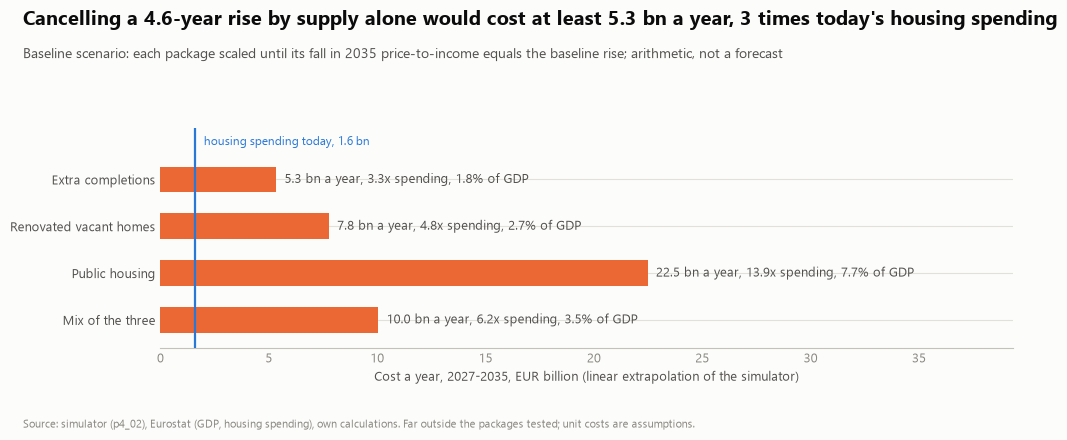

In [4]:
completions = supply.national_flows(panel)["completed_n"]
tax = interim.read("eurostat_property_tax").set_index("year")
spend = interim.read("eurostat_housing_spending")
pt = spend[(spend["geo"] == "PT") & (spend["year"] == 2024)].iloc[0]
housing_m = float(pt["housing_development_eur_m"] + pt["housing_benefits_eur_m"])
gdp_m = float(tax.loc[2024, "gdp_eur_m"])
supply_rows = effects.loc[["construction", "renovation", "public", "supply_mix"]]
offset = funding.offset_requirement(supply_rows, rise, YEARS, gdp_m, housing_m)
offset["units_a_year_gross"] = pd.Series(
    {pkg: sum(A.packages[pkg].values()) * offset.loc[pkg, "scale"] for pkg in offset.index}
)
offset["units_vs_peak_completions"] = offset["units_a_year_gross"] / completions.max()
style.save_table(offset.round(2).reset_index(), "p4", "policy_offset_requirement")
labels = {
    "construction": "Extra completions",
    "renovation": "Renovated vacant homes",
    "public": "Public housing",
    "supply_mix": "Mix of the three",
}
fig = charts.offset_cost(offset, labels, housing_m / 1000, rise)
style.save_fig(fig, "p4", "policy_offset_cost")
offset.round(2)

## Key numbers

In [5]:
print(
    f"baseline rise {rise:.2f} years, GDP 2024 {gdp_m:,.0f} EUR m, housing spending 2024 {housing_m:,.0f} EUR m; "
    f"completions peak {completions.max():,.0f} ({completions.idxmax()}), 2025 {completions.loc[2025]:,.0f}"
)
for pkg, r in offset.iterrows():
    print(
        f"  {pkg}: x{r.scale:.1f} the tested package, {r.yearly_cost_bn:.1f} bn a year ({r.yearly_cost_gdp_pct:.1f}% of GDP, "
        f"{r.yearly_cost_vs_housing_spending:.1f}x spending), {r.units_a_year_gross:,.0f} units a year ({r.units_vs_peak_completions:.1f}x the peak of completions)"
    )
for pkg, r in card.iterrows():
    print(
        f"  {pkg}: gain {r.pti_gain_p50:+.2f} ({r.pti_gain_p10:+.2f} to {r.pti_gain_p90:+.2f}) years for {r.cost_bn:.1f} bn, {r.who_pays}"
    )

baseline rise 4.58 years, GDP 2024 291,153 EUR m, housing spending 2024 1,615 EUR m; completions peak 125,708 (2002), 2025 27,301
  construction: x16.7 the tested package, 5.3 bn a year (1.8% of GDP, 3.3x spending), 167,398 units a year (1.3x the peak of completions)
  renovation: x14.2 the tested package, 7.8 bn a year (2.7% of GDP, 4.8x spending), 141,804 units a year (1.1x the peak of completions)
  public: x28.4 the tested package, 22.5 bn a year (7.7% of GDP, 13.9x spending), 141,936 units a year (1.1x the peak of completions)
  supply_mix: x12.1 the tested package, 10.0 bn a year (3.5% of GDP, 6.2x spending), 151,111 units a year (1.2x the peak of completions)
  construction: gain +0.27 (+0.19 to +0.37) years for 2.9 bn, State (assumed)
  renovation: gain +0.32 (+0.23 to +0.44) years for 4.9 bn, State (assumed)
  public: gain +0.16 (+0.12 to +0.22) years for 7.1 bn, State (assumed)
  supply_mix: gain +0.38 (+0.28 to +0.50) years for 7.5 bn, State (assumed)
  imi_cut: gain -0.07 (